# Neural Networks Project

Implementation of ANN and Decision tree algorithm comparison on the Adult income dataset.

Step 1: import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Step 2: Data Preproccessing

In [ ]:
import pandas as pd
df = pd.read_csv('/content/sample_data/adult.csv')

print(df.head())
df.info()
print(df.describe())

   age  workclass  fnlwgt     education  educational-num      marital-status  \
0   25    Private  226802          11th                7       Never-married   
1   38    Private   89814       HS-grad                9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm               12  Married-civ-spouse   
3   44    Private  160323  Some-college               10  Married-civ-spouse   
4   18          ?  103497  Some-college               10       Never-married   

          occupation relationship   race  gender  capital-gain  capital-loss  \
0  Machine-op-inspct    Own-child  Black    Male             0             0   
1    Farming-fishing      Husband  White    Male             0             0   
2    Protective-serv      Husband  White    Male             0             0   
3  Machine-op-inspct      Husband  Black    Male          7688             0   
4                  ?    Own-child  White  Female             0             0   

   hours-per-week native-country incom

Handling missing values.


In [ ]:
#all missing values have been replaced with ? sign so we assign them as null
df = df.replace('?', np.nan)
print(df.isnull().sum())
df.head(5)

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [ ]:
print(df.isnull().sum())

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64


In [ ]:
# Replace with the most frequent value which is 'united-states'
print('the null values before replacment',df['native-country'].isnull().sum())# Count null values
df['native-country'] = df['native-country'].fillna(df['native-country'].mode()[0])

print(df['native-country'].isnull().sum())

the null values before replacment 857
0


In [ ]:
# Replace with the most frequent value which is 'Private'
print('the null values before replacment',df['workclass'].isnull().sum())  # Count null values
df['workclass'] = df['workclass'].fillna(df['workclass'].mode()[0])

print('the null values after replacment',df['workclass'].isnull().sum())  # Count null values


the null values before replacment 2799
the null values after replacment 0


In [ ]:
#Replace with the most frequent value which is Prof-specialty
print('the null values before replacment',df['occupation'].isnull().sum())  # Count null values
df['occupation'] = df['occupation'].fillna(df['occupation'].mode()[0])

print('the null values after replacment',df['occupation'].isnull().sum()) # Count null values

the null values before replacment 2809
the null values after replacment 0


In [ ]:
#making sure no missing values are there
df = df.replace('?', np.nan)
print(df.isnull().sum())

age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64


Duplicated values

In [ ]:
print('there is',df.duplicated().sum(), 'duplicated values')
df = df.drop_duplicates()

there is 53 duplicated values


changing all types to accurate representation

In [ ]:
#checking the types of
print(df.dtypes)

categorical_columns = df.select_dtypes(include=['object']).columns
for col in categorical_columns:
     df.loc[:, col] = df[col].astype('category')
print(df.dtypes)

age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object
age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object


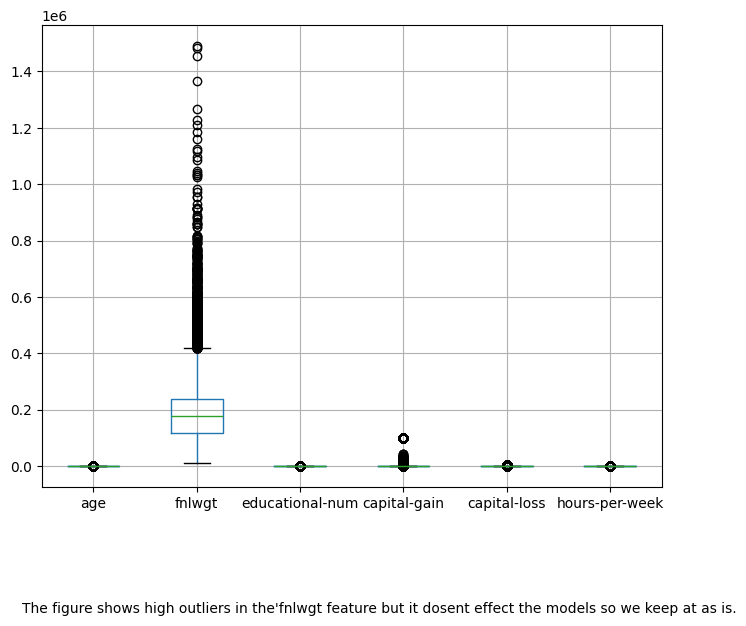

In [ ]:
#outliers
columns_to_plot = ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
df.boxplot(column=columns_to_plot, figsize=(8, 6))
plt.figtext(0.1,-0.1,"The figure shows high outliers in the'fnlwgt feature but it dosent effect the models so we keep at as is.")
plt.show()

plotting numerical features as histogram to test skewness but since the skewness of these exact features dosent affect our model so we keep it as is.

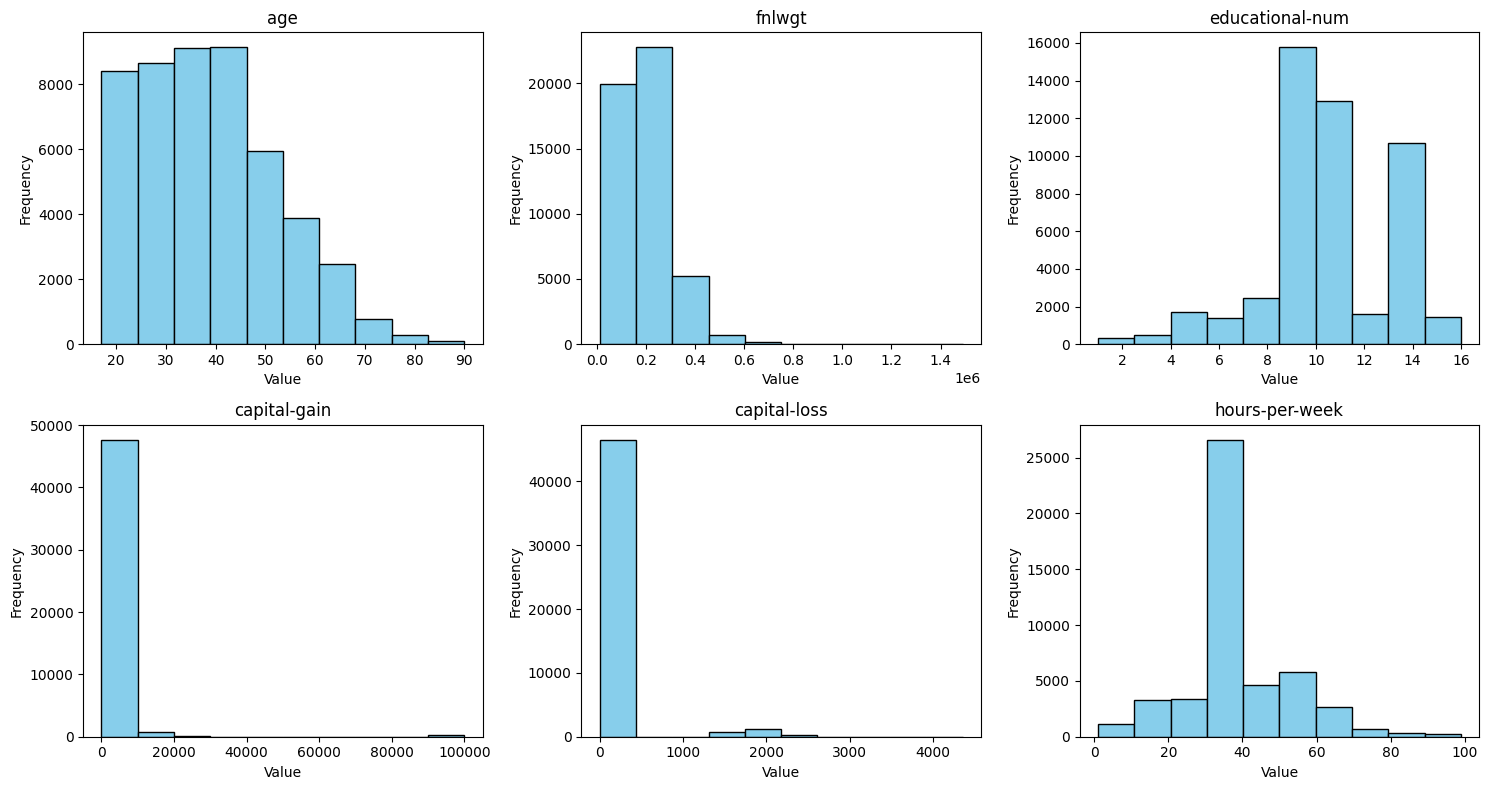

In [ ]:
features = ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

# Plot histograms for each feature
for i, feature in enumerate(features):
    axes[i].hist(df[feature], bins=10, color='skyblue', edgecolor='black')
    axes[i].set_title(feature)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Adjust layout for better spacing
plt.tight_layout()
plt.show()


Encoding ordinal categorical features

In [ ]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, MinMaxScaler


encoded_df = pd.get_dummies(df, columns=['workclass','marital-status','occupation','relationship','race','native-country'], drop_first=True)
print(encoded_df)# ,drop_first=False)

df['income'] = LabelEncoder().fit_transform(df['income'])
df['gender'] = LabelEncoder().fit_transform(df['income'])

print(df)

       age  fnlwgt     education  educational-num  gender  capital-gain  \
0       25  226802          11th                7    Male             0   
1       38   89814       HS-grad                9    Male             0   
2       28  336951    Assoc-acdm               12    Male             0   
3       44  160323  Some-college               10    Male          7688   
4       18  103497  Some-college               10  Female             0   
...    ...     ...           ...              ...     ...           ...   
48837   27  257302    Assoc-acdm               12  Female             0   
48838   40  154374       HS-grad                9    Male             0   
48839   58  151910       HS-grad                9  Female             0   
48840   22  201490       HS-grad                9    Male             0   
48841   52  287927       HS-grad                9  Female         15024   

       capital-loss  hours-per-week income  workclass_Local-gov  ...  \
0                 0        

Normilizing numerical features using min max scaler


In [ ]:
scaler = MinMaxScaler()

columns_to_normalize = ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']
df[columns_to_normalize] = scaler.fit_transform(df[columns_to_normalize])

#check if the values are between 0,1 then the normalization is corecct
df.describe()


,age,fnlwgt,educational-num,gender,capital-gain,capital-loss,hours-per-week,income
count,48789.000000,48789.000000,48789.000000,48789.000000,48789.000000,48789.000000,48789.000000,48789.000000
mean,0.296618,0.120007,0.605254,0.239419,0.010803,0.020110,0.402305,0.239419
std,0.187787,0.071455,0.171338,0.426733,0.074561,0.092565,0.126458,0.426733
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.150685,0.071219,0.533333,0.000000,0.000000,0.000000,0.397959,0.000000
50%,0.273973,0.112207,0.600000,0.000000,0.000000,0.000000,0.397959,0.000000
75%,0.424658,0.152439,0.733333,0.000000,0.000000,0.000000,0.448980,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
# clean data
df.to_csv('df.csv', index=False)
# preproccesed, clean and transformed data(encoding,normalization)
encoded_df.to_csv('encoded.csv', index= False)

Step 2: Split the data set

In [ ]:
X = df.drop('income', axis=1)
y = df['income']

# Split into training,validation 80% and test set 20%
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Split the training 75% ,validation set into training and validation 25%
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.25, random_state=42)

print(f"Training set size: {X_train.shape}")
print(f"Validation set size: {X_val.shape}")
print(f"Test set size: {X_test.shape}")


Training set size: (29273, 14)
Validation set size: (9758, 14)
Test set size: (9758, 14)


# **Decision Tree:**
A model that splits data into branches based on decision rules to classify outcomes, evaluated using accuracy and confusion matrix.

In [ ]:


from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("/content/sample_data/adult.csv")

df = df.replace('?', np.nan)
df = df.dropna()


label_encoders = {}
for column in df.select_dtypes(include='object').columns:
    label_encoders[column] = LabelEncoder()
    df[column] = label_encoders[column].fit_transform(df[column])

# Split features and target variable
X = df.drop("income", axis=1)
y = df["income"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Decision Tree Model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

#Predict and evaluate Decision Tree
y_pred_dt = dt_model.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Decision Tree Classification Report:\n", classification_report(y_test, y_pred_dt))



Decision Tree Accuracy: 0.8064123825317855
Decision Tree Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.87      0.87      6842
           1       0.60      0.62      0.61      2203

    accuracy                           0.81      9045
   macro avg       0.74      0.74      0.74      9045
weighted avg       0.81      0.81      0.81      9045



# **ANN:**
## A neural network with input, hidden, and output layers, trained to predict outcomes using activation functions and evaluated for accuracy.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


# Normalize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#  Build the ANN model
ann_model = Sequential([
    Dense(64, input_dim=X_train.shape[1], activation='relu'),  # First hidden layer
    Dense(32, activation='relu'),  # Second hidden layer
    Dense(1, activation='sigmoid')  # Output layer for binary classification
])

# Compile the model
ann_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the ANN model
ann_model.fit(X_train_scaled, y_train, epochs=5, batch_size=32, verbose=1)

#Evaluate the ANN model
y_pred_ann = (ann_model.predict(X_test_scaled) > 0.5).astype("int32")

print("ANN Accuracy:", accuracy_score(y_test, y_pred_ann))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ann))
print("Classification Report:\n", classification_report(y_test, y_pred_ann))


Epoch 1/5


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1131/1131 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8014 - loss: 0.4183
Epoch 2/5
1131/1131 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8450 - loss: 0.3313
Epoch 3/5
1131/1131 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8430 - loss: 0.3273
Epoch 4/5
1131/1131 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8464 - loss: 0.3282
Epoch 5/5
1131/1131 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8458 - loss: 0.3314
283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
ANN Accuracy: 0.8482034273079049
Confusion Matrix:
 [[6295  547]
 [ 826 1377]]
Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.92      0.90      6842
           1       0.72      0.63      0.67      2203

    accuracy                           0.85      9045
   macro avg       0.80      0.77      0.78      9045
weighted avg       0.84      0.85      0.84      9045



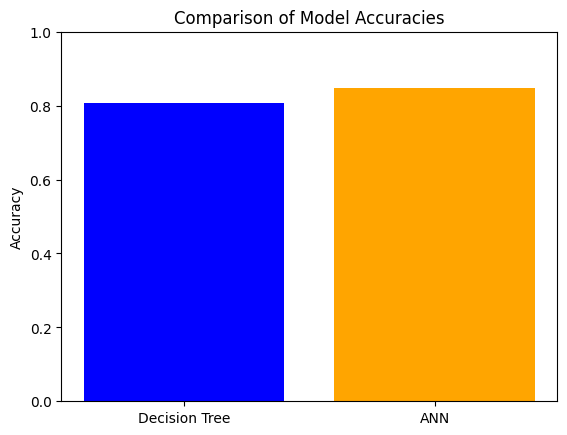

In [ ]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
accuracy_ann = accuracy_score(y_test, y_pred_ann)

models = ['Decision Tree', 'ANN']
accuracies = [accuracy_dt, accuracy_ann]

plt.bar(models, accuracies, color=['blue', 'orange'])
plt.title('Comparison of Model Accuracies')
plt.ylabel('Accuracy')
plt.ylim(0, 1)  # Accuracy range (0 to 1)
plt.show()


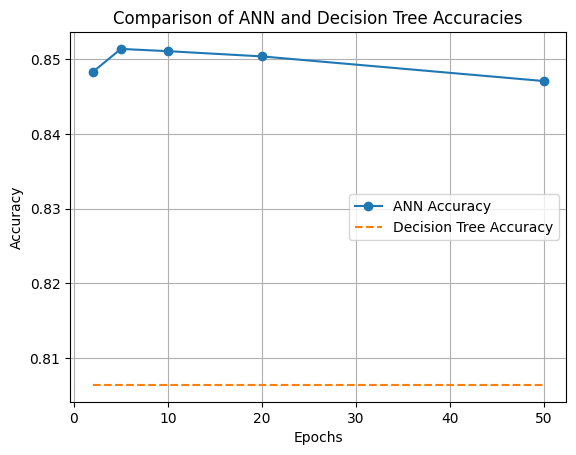

In [ ]:
epochs = [2, 5, 10, 20, 50]
accuracy_ann = [0.8483, 0.8514, 0.8511, 0.8504, 0.8471]
accuracy_dt = [0.8064] * len(epochs)


plt.plot(epochs, accuracy_ann, label='ANN Accuracy', marker='o')
plt.plot(epochs, accuracy_dt, label='Decision Tree Accuracy', linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Comparison of ANN and Decision Tree Accuracies')
plt.legend()
plt.grid()
plt.show()